In [1]:
import pandas as pd

In [2]:
df = pd.read_csv('2024_25_mlb_pitches.csv')

In [3]:
print(*df.columns)

Unnamed: 0 pitch_type game_date release_speed release_pos_x release_pos_z player_name batter pitcher events description spin_dir spin_rate_deprecated break_angle_deprecated break_length_deprecated zone des game_type stand p_throws home_team away_team type hit_location bb_type balls strikes game_year pfx_x pfx_z plate_x plate_z on_3b on_2b on_1b outs_when_up inning inning_topbot hc_x hc_y tfs_deprecated tfs_zulu_deprecated umpire sv_id vx0 vy0 vz0 ax ay az sz_top sz_bot hit_distance_sc launch_speed launch_angle effective_speed release_spin_rate release_extension game_pk fielder_2 fielder_3 fielder_4 fielder_5 fielder_6 fielder_7 fielder_8 fielder_9 release_pos_y estimated_ba_using_speedangle estimated_woba_using_speedangle woba_value woba_denom babip_value iso_value launch_speed_angle at_bat_number pitch_number pitch_name home_score away_score bat_score fld_score post_away_score post_home_score post_bat_score post_fld_score if_fielding_alignment of_fielding_alignment spin_axis delta_hom

In [4]:
import pandas as pd
import statsmodels.api as sm
import joblib

# 1. Load the Model and Scaler
model = sm.load("zonespeed_model.pkl")
scaler = joblib.load("zonespeed_scaler.joblib")

# --- DEBUGGING STEP ---
print("Actual columns in your df:", df.columns.tolist())

# 2. Map and Rename
# We use a dictionary to be explicit.
# Make sure 'release_speed' and 'ay' match your CSV exactly (check for spaces!)
mapping = {'release_speed': 'RelSpeed', 'ay': 'ay0'}
df_input = df.rename(columns=mapping)

# 3. Define the exact features used during training
# THE ORDER MUST MATCH THE ORDER USED IN NOTEBOOK 1
feature_cols = ['RelSpeed', 'ay0']

# --- VALIDATION STEP ---
missing = [col for col in feature_cols if col not in df_input.columns]
if missing:
    raise KeyError(f"The following required columns are missing after renaming: {missing}. "
                   f"Check if 'release_speed' or 'ay' are spelled correctly in your CSV.")

# 4. Scale and Predict
# We slice only the columns we need
X_raw = df_input[feature_cols]

# Step 5: Scale (returns a numpy array)
X_scaled = scaler.transform(X_raw)

# Step 6: Reconstruct DataFrame for Statsmodels
X_scaled_df = pd.DataFrame(X_scaled, columns=feature_cols, index=df.index)
X_scaled_df = sm.add_constant(X_scaled_df, has_constant='add')

# Step 7: Predict
df['zone_speed'] = model.predict(X_scaled_df)

print("\nSuccess! Here are the first 5 predictions:")
print(df[['RelSpeed', 'zone_speed']].head() if 'RelSpeed' in df.columns else df.iloc[:5, -1:])

Actual columns in your df: ['Unnamed: 0', 'pitch_type', 'game_date', 'release_speed', 'release_pos_x', 'release_pos_z', 'player_name', 'batter', 'pitcher', 'events', 'description', 'spin_dir', 'spin_rate_deprecated', 'break_angle_deprecated', 'break_length_deprecated', 'zone', 'des', 'game_type', 'stand', 'p_throws', 'home_team', 'away_team', 'type', 'hit_location', 'bb_type', 'balls', 'strikes', 'game_year', 'pfx_x', 'pfx_z', 'plate_x', 'plate_z', 'on_3b', 'on_2b', 'on_1b', 'outs_when_up', 'inning', 'inning_topbot', 'hc_x', 'hc_y', 'tfs_deprecated', 'tfs_zulu_deprecated', 'umpire', 'sv_id', 'vx0', 'vy0', 'vz0', 'ax', 'ay', 'az', 'sz_top', 'sz_bot', 'hit_distance_sc', 'launch_speed', 'launch_angle', 'effective_speed', 'release_spin_rate', 'release_extension', 'game_pk', 'fielder_2', 'fielder_3', 'fielder_4', 'fielder_5', 'fielder_6', 'fielder_7', 'fielder_8', 'fielder_9', 'release_pos_y', 'estimated_ba_using_speedangle', 'estimated_woba_using_speedangle', 'woba_value', 'woba_denom', 'b

In [5]:
df['hit_location']

0          9.0
1          5.0
2          6.0
3          7.0
4          NaN
          ... 
1531038    NaN
1531039    8.0
1531040    NaN
1531041    NaN
1531042    NaN
Name: hit_location, Length: 1531043, dtype: float64

In [6]:
df['release_speed'].isna().value_counts()

release_speed
False    1495601
True       35442
Name: count, dtype: int64

In [7]:
df['ay'].isna().value_counts()

ay
False    1495597
True       35446
Name: count, dtype: int64

In [8]:
df['zone_speed'].isna().value_counts()

zone_speed
False    1495594
True       35449
Name: count, dtype: int64

In [9]:
# 1. Define the columns needed for the calculation
calc_cols = ['launch_speed', 'zone_speed', 'bat_speed']

# 2. Drop rows with NaNs in these specific columns
df_clean = df.dropna(subset=calc_cols).copy()

# 3. Calculate eA (Efficiency of the hit)
# eA = (Launch Speed - Bat Speed) / (Zone Speed + Bat Speed)
df_clean['eA'] = (df_clean['launch_speed'] - df_clean['bat_speed']) / \
                 (df_clean['zone_speed'] + df_clean['bat_speed'])

# 4. View results
print(df_clean[['launch_speed', 'zone_speed', 'bat_speed', 'eA']].head())

       launch_speed  zone_speed  bat_speed        eA
59953          98.8   86.346076       56.7  0.294311
59960          79.8   86.400960       62.4  0.116935
59961          69.5   86.542588       55.7  0.097017
59967          79.3   85.902841       57.4  0.152823
59969          79.4   86.879170       70.7  0.055210


In [10]:
import matplotlib.pyplot as plt

In [11]:
df_clean['eA'].describe()

count    458931.000000
mean          0.081220
std           0.094568
min          -0.476109
25%           0.019287
50%           0.083399
75%           0.154955
max           0.935029
Name: eA, dtype: float64

In [12]:
df_clean.columns

Index(['Unnamed: 0', 'pitch_type', 'game_date', 'release_speed',
       'release_pos_x', 'release_pos_z', 'player_name', 'batter', 'pitcher',
       'events',
       ...
       'api_break_x_arm', 'api_break_x_batter_in', 'arm_angle', 'attack_angle',
       'attack_direction', 'swing_path_tilt',
       'intercept_ball_minus_batter_pos_x_inches',
       'intercept_ball_minus_batter_pos_y_inches', 'zone_speed', 'eA'],
      dtype='object', length=121)

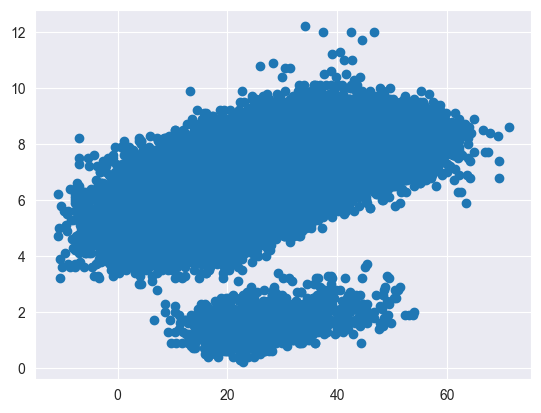

In [13]:
plt.scatter(df_clean['intercept_ball_minus_batter_pos_y_inches'], df_clean['swing_length'])

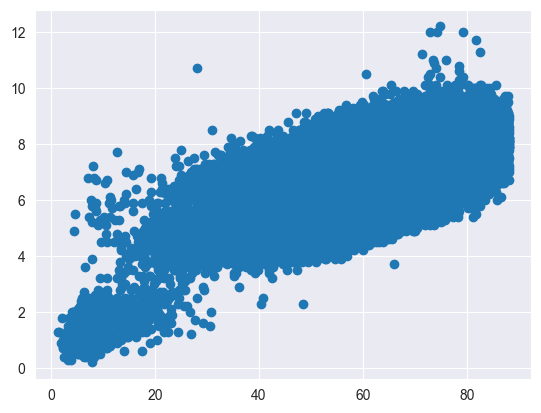

In [14]:
plt.scatter(df_clean['bat_speed'], df_clean['swing_length'])

In [15]:
df_clean['hit_location'].value_counts()

hit_location
8.0    41511
9.0    38211
7.0    37018
6.0    29000
4.0    27161
5.0    24918
3.0    17583
1.0     7870
2.0     2133
Name: count, dtype: int64

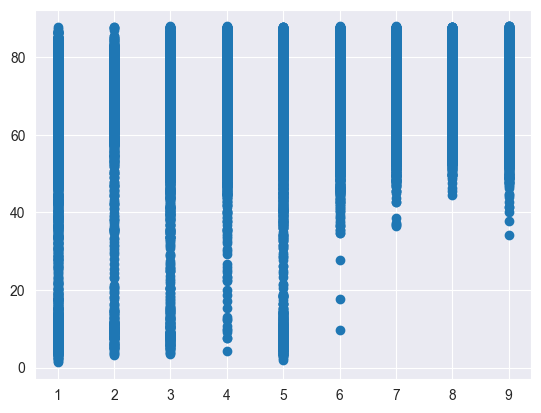

In [16]:
plt.scatter(df_clean['hit_location'], df_clean['bat_speed'])

(array([   712.,    467.,    556.,   1034.,   1574.,   3621.,  26178.,
        176894., 226038.,  21857.]),
 array([ 1.3 ,  9.97, 18.64, 27.31, 35.98, 44.65, 53.32, 61.99, 70.66,
        79.33, 88.  ]),
 <BarContainer object of 10 artists>)

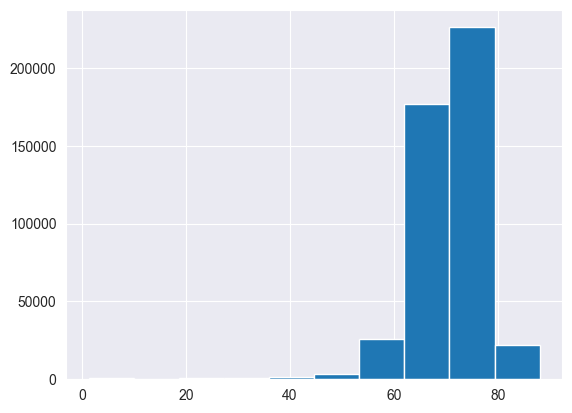

In [17]:
plt.hist(df_clean['bat_speed'])

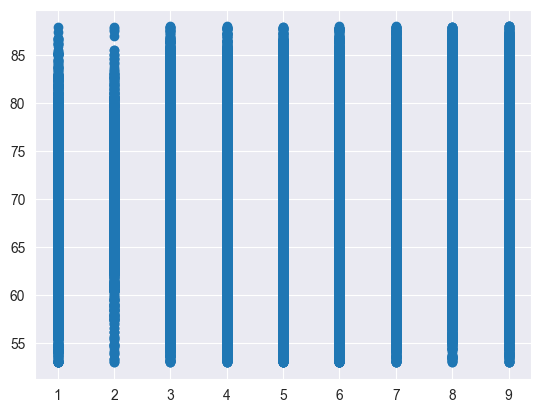

In [18]:
plt.scatter(df_clean['hit_location'][df_clean['bat_speed'] >= 53], df_clean['bat_speed'][df_clean['bat_speed'] >= 53])

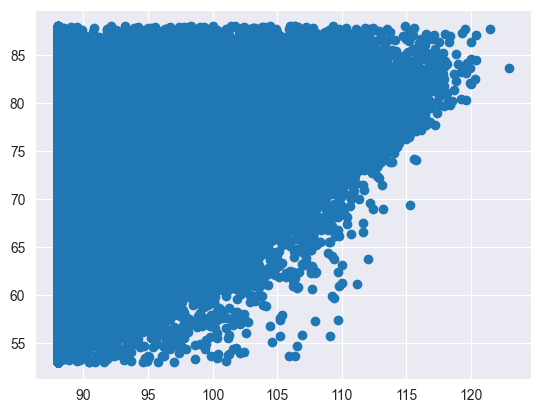

In [19]:
plt.scatter(df_clean['hyper_speed'][df_clean['bat_speed'] >= 53], df_clean['bat_speed'][df_clean['bat_speed'] >= 53])

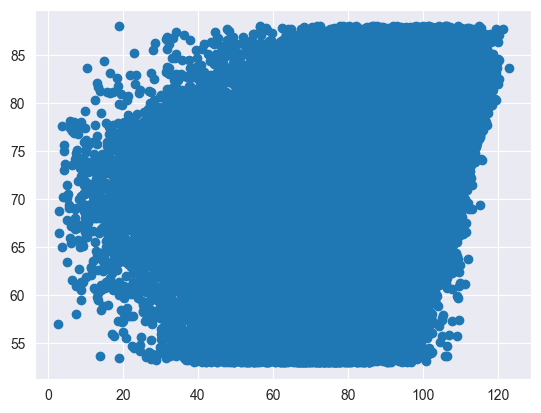

In [20]:
plt.scatter(df_clean['launch_speed'][df_clean['bat_speed'] >= 53], df_clean['bat_speed'][df_clean['bat_speed'] >= 53])

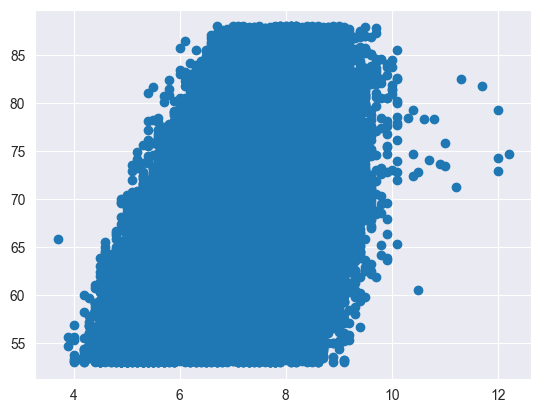

In [21]:
plt.scatter(df_clean['swing_length'][df_clean['bat_speed'] >= 53], df_clean['bat_speed'][df_clean['bat_speed'] >= 53])

In [22]:
df_clean['efficiency'] = df['launch_speed'] / df['zone_speed']
# Create a power-weighted feature
# This helps the model distinguish between a 105mph EV and a 115mph EV
df_clean['ev_squared'] = df_clean['launch_speed'] ** 2

df_clean['bat_acceleration'] = 0.03343 * df_clean['bat_speed']**2 / df_clean['swing_length']

In [23]:
import pandas as pd
import numpy as np
from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split, RandomizedSearchCV, GridSearchCV
from sklearn.metrics import mean_squared_error, r2_score

# --- 1. FEATURE SELECTION ---
features = ['zone_speed', 'launch_angle', 'launch_speed']
target = 'bat_speed'

df_model = df_clean[df_clean['bat_speed'] >= 53].dropna(subset=features + [target]).copy()
df_dev, df_holdout = train_test_split(df_model, test_size=0.2, random_state=42)
X_dev, y_dev = df_dev[features], df_dev[target]

# --- 2. STAGE 1: RANDOMIZED SEARCH (Broad Strokes) ---
# We focus on the big levers: depth, learning rate, and sampling
rs_space = {
    'n_estimators': [200], # Set high, we can use early stopping or learning rate to control
    'max_depth': [3, 6, 9],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'subsample': [0.7, 0.8, 0.9],
    'colsample_bytree': [0.7, 0.8, 1.0],
    'gamma': [0, 1, 5],
}

rs = RandomizedSearchCV(
    XGBRegressor(random_state=42, tree_method='hist', n_jobs=-1),
    param_distributions=rs_space,
    n_iter=20,
    cv=3,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
    random_state=42,
)
rs.fit(X_dev, y_dev)

# --- 3. STAGE 2: GRID SEARCH (Fine-Tuning) ---
# We take the best parameters from RS and "zoom in" on the most sensitive ones
best = rs.best_params_

gs_space = {
    'max_depth': [best['max_depth'] - 1, best['max_depth']],
    'learning_rate': [best['learning_rate'] * 0.8, best['learning_rate']],
    'subsample': [best['subsample']],
    'colsample_bytree': [best['colsample_bytree']],
    'gamma': [best['gamma']],
    'n_estimators': [best['n_estimators']]
}

gs = GridSearchCV(
    XGBRegressor(
        n_estimators=best['n_estimators'],
        colsample_bytree=best['colsample_bytree'],
        gamma=best['gamma'],
        tree_method='hist',
        random_state=42
    ),
    param_grid=gs_space,
    cv=3,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
)
gs.fit(X_dev, y_dev)

# --- 4. FINAL MODEL & EVALUATION ---
final_model = gs.best_estimator_

df_holdout = df_holdout.copy()
df_holdout['pred_bat_speed'] = final_model.predict(df_holdout[features])

# Calculate Player Level Stats
min_swings = 5
player_stats = df_holdout.groupby('batter').agg({
    'bat_speed': 'mean',
    'pred_bat_speed': 'mean',
    'launch_speed': 'count'
}).query(f'launch_speed >= {min_swings}')

print(f"Best Params: {gs.best_params_}")
print(f"Final Holdout R2: {r2_score(df_holdout['bat_speed'], df_holdout['pred_bat_speed']):.4f}")
print(f"Aggregated Player Correlation (N={min_swings}+): {player_stats['bat_speed'].corr(player_stats['pred_bat_speed']):.4f}")

Best Params: {'colsample_bytree': 1.0, 'gamma': 1, 'learning_rate': 0.04000000000000001, 'max_depth': 6, 'n_estimators': 200, 'subsample': 0.9}
Final Holdout R2: 0.1503
Aggregated Player Correlation (N=5+): 0.6416


In [24]:
# Stage 1 & 2: Random + Grid Search (Simplified)
# ... [Insert the Search code from previous steps here, but pass X_train_val directly] ...

# Final Model Evaluation
def get_metrics(model, X, y_true):
    preds = model.predict(X)
    return np.sqrt(mean_squared_error(y_true, preds)), r2_score(y_true, preds)

# Check individual swing performance
train_rmse, train_r2 = get_metrics(final_model, X_dev, y_dev)
holdout_rmse, holdout_r2 = get_metrics(final_model, df_holdout[features], df_holdout[target])

print(f"Set      | RMSE   | R2")
print(f"Train    | {train_rmse:.2f} | {train_r2:.3f}")
print(f"Holdout  | {holdout_rmse:.2f} | {holdout_r2:.3f}")

Set      | RMSE   | R2
Train    | 4.95 | 0.160
Holdout  | 4.99 | 0.150


In [25]:
import numpy as np
import pandas as pd
from scipy import stats

# --- CRONBACH'S ALPHA RELIABILITY ANALYSIS ON pred_bat_speed ---
# Treat each swing as an "item" and each player as a "subject".
# We pivot to a player x swing matrix, then compute alpha.

# --- 1. BUILD THE PLAYER x SWING MATRIX ---
# Assign swing index per player (swing 1, 2, 3, ... N)
df_holdout_sorted = df_holdout.sort_values('batter').copy()
df_holdout_sorted['swing_num'] = df_holdout_sorted.groupby('batter').cumcount() + 1

def cronbach_alpha(df_matrix):
    """
    df_matrix: rows = subjects (players), columns = items (swings).
    NaN = player didn't have that many swings (listwise or pairwise handled below).
    """
    df_matrix = df_matrix.dropna()  # listwise: only players with all k swings
    n_subjects, k = df_matrix.shape

    if k < 2 or n_subjects < 2:
        return np.nan, np.nan, np.nan

    item_vars  = df_matrix.var(axis=0, ddof=1)
    total_var  = df_matrix.sum(axis=1).var(ddof=1)

    alpha = (k / (k - 1)) * (1 - item_vars.sum() / total_var)
    sem   = df_matrix.sum(axis=1).std(ddof=1) * np.sqrt(1 - alpha)

    return alpha, sem, n_subjects

# --- 2. ALPHA AT EACH SWING COUNT (k = 2 to max_k) ---
max_k   = 30
records = []

for k in range(2, max_k + 1,  2):
    subset = df_holdout_sorted[df_holdout_sorted['swing_num'] <= k]
    matrix = subset.pivot(index='batter', columns='swing_num', values='pred_bat_speed')
    matrix = matrix.iloc[:, :k]  # enforce exactly k columns

    alpha, sem, n = cronbach_alpha(matrix)

    records.append({
        'k_swings':  k,
        'alpha':     alpha,
        'sem':       sem,
        'n_players': n
    })

results = pd.DataFrame(records)
print(results.round(3).to_string(index=False))

# --- 3. SPEARMAN-BROWN PROPHECY ---
# Given alpha at baseline k swings, project what alpha would be
# with more swings — useful for setting a minimum swing threshold.

baseline_k     = 5
baseline_alpha = results.loc[results['k_swings'] == baseline_k, 'alpha'].values[0]

def spearman_brown(alpha_k, k_base, k_target):
    """Project reliability from k_base items to k_target items."""
    n = k_target / k_base
    return (n * alpha_k) / (1 + (n - 1) * alpha_k)

results['sb_projected_alpha'] = results['k_swings'].apply(
    lambda k: spearman_brown(baseline_alpha, baseline_k, k)
)

# --- 4. FIND MINIMUM SWINGS TO HIT TARGET RELIABILITY ---
target_alpha = 0.70
min_k_actual    = results.loc[results['alpha']            >= target_alpha, 'k_swings'].min()
min_k_projected = results.loc[results['sb_projected_alpha'] >= target_alpha, 'k_swings'].min()

print(f"\nBaseline alpha at k={baseline_k}: {baseline_alpha:.3f}")
print(f"Swings needed for α ≥ {target_alpha} (observed):   {min_k_actual}")
print(f"Swings needed for α ≥ {target_alpha} (SB projected): {min_k_projected}")

# --- 5. PLOT ---
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

fig = plt.figure(figsize=(14, 5))
gs  = gridspec.GridSpec(1, 2, wspace=0.35)

# Left: observed alpha + SB projection
ax1 = fig.add_subplot(gs[0])
ax1.plot(results['k_swings'], results['alpha'],            color='steelblue', linewidth=2,   label='Observed α')
ax1.plot(results['k_swings'], results['sb_projected_alpha'], color='orange',  linewidth=1.5, linestyle='--', label=f'SB projection (base k={baseline_k})')
ax1.axhline(target_alpha, color='crimson', linestyle=':', linewidth=1.2, label=f'Target α={target_alpha}')
ax1.axhline(0.80,         color='gray',    linestyle=':', linewidth=1.0, label='α=0.80')
ax1.set_xlabel('Swings (k)',  fontsize=11)
ax1.set_ylabel('Cronbach α',  fontsize=11)
ax1.set_title('Reliability vs Swing Count', fontsize=12)
ax1.set_ylim(0, 1)
ax1.legend(fontsize=9)
ax1.grid(True, alpha=0.2)

# Right: SEM across swing counts
ax2 = fig.add_subplot(gs[1])
ax2.plot(results['k_swings'], results['sem'], color='steelblue', linewidth=2)
ax2.set_xlabel('Swings (k)', fontsize=11)
ax2.set_ylabel('SEM (mph)',   fontsize=11)
ax2.set_title('Standard Error of Measurement vs Swing Count', fontsize=12)
ax2.grid(True, alpha=0.2)

fig.suptitle('pred_bat_speed — Cronbach α Reliability Analysis', fontsize=13, y=1.02)
plt.savefig('reliability_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

 k_swings  alpha    sem  n_players
        2 -0.067  2.850        762
        4  0.088  3.992        725
        6  0.162  4.869        709
        8  0.228  5.645        692
       10  0.234  6.400        676
       12  0.270  7.053        661
       14  0.295  7.690        643
       16  0.333  8.196        626
       18  0.342  8.659        612
       20  0.377  9.146        600
       22  0.408  9.563        590
       24  0.422  9.990        571
       26  0.444 10.361        563
       28  0.452 10.745        557
       30  0.465 11.121        551


IndexError: index 0 is out of bounds for axis 0 with size 0

In [31]:
# --- 1. REVISIT PHYSICS WITH CORRECT INPUT ---
# Your original features had zone_speed — that's pitch speed AT the plate,
# which is what the collision equation actually needs. This is likely why
# the physics R² was -7: release_speed was wrong input entirely.

# Solve for q directly using actual bat_speed where you have it
# From: launch_speed = q * zone_speed + (1 + q) * bat_speed
# Rearranging: q = (launch_speed - bat_speed) / (zone_speed + bat_speed)
np.random.seed(42)


df_clean['q_empirical'] = (
    (df_clean['launch_speed'] - df_clean['bat_speed']) /
    (df_clean['zone_speed']   + df_clean['bat_speed'])
)

# --- QUALITY FILTER ---
# Physical bounds: q must be positive (energy not created from nothing)
# and below ~0.50 (hard cap for wood bat COR in literature).
# Your 0.05–0.40 filter excludes mishits, foul tips, and measurement noise.
q_mask = df_clean['q_empirical'].between(0.05, 0.40)

q_mean = df_clean.loc[q_mask, 'q_empirical'].mean()
q_std  = df_clean.loc[q_mask, 'q_empirical'].std()


print(f"Mean empirical q: {q_mean:.4f}")
print(f"Empirical q std: {q_std:.4f}")


df_clean['bat_speed_physics'] = (
    (df_clean['launch_speed'] - q_mean * df_clean['zone_speed'])
    / (1 + q_mean)
)


# Now you can condition q on observable features
# e.g. does it vary by pitch type, location, contact quality?
print(df_clean.groupby('pitch_type')['q_empirical'].agg(['mean','std','count']).round(4))
print(df_clean.groupby(pd.cut(df_clean['launch_angle'], bins=[-90,-10,10,25,45,90]))['q_empirical'].mean().round(4))

q = df_clean['q_stochastic']

mask = df_clean['bat_speed'].notna() & df_clean['bat_speed_physics'].notna()
print(f"Physics R² (zone_speed): {r2_score(df_clean.loc[mask, 'bat_speed'], df_clean.loc[mask, 'bat_speed_physics']):.4f}")

# If this R² is high, you're essentially done — the physics solves it
# and everything below is just refining the contact-quality correction

# --- 2. CONTACT QUALITY PROXIES (no player identity) ---
# These capture how well the batter squared it up, which is the main
# thing that breaks the physics estimate (off-center hits bleed energy)

# Spray angle — pull-side contact generally means better timing/swing path
if 'hc_x' in df_clean.columns and 'hc_y' in df_clean.columns:
    df_clean['spray_angle'] = np.degrees(
        np.arctan((df_clean['hc_x'] - 125.42) / (198.27 - df_clean['hc_y']))
    )

# Smash factor — actual contact efficiency, no player info embedded
df_clean['smash_factor'] = df_clean['launch_speed'] / df_clean['bat_speed_physics'].clip(lower=40)

# Speed drop: how much exit velo fell short of physics prediction
df_clean['physics_residual_proxy'] = df_clean['launch_speed'] - (
    q * df_clean['zone_speed'] + (1 + q) * df_clean['bat_speed_physics']
)

# Plate location difficulty — edge/low pitches harder to square up
df_clean['pitch_difficulty'] = np.sqrt(df_clean['plate_x']**2 +
                                        (df_clean['plate_z'] - 2.5)**2)

df_clean['count_leverage'] = df_clean['balls'] - df_clean['strikes']

df_clean['vyf'] = - np.sqrt(df_clean['vy0']**2 - (2 * df_clean['ay'] * (df_clean['release_pos_y'] - 1.417)))
df_clean['t'] = (df_clean['vyf'] - df_clean['vy0'])/df_clean['ay']
df_clean['vzf'] = df_clean['vz0'] + (df_clean['az'] * df_clean['t'])
df_clean['vxf'] = df_clean['vx0'] + (df_clean['ax'] * df_clean['t'])

df_clean['VAA'] = - np.arctan(df_clean['vzf']/df_clean['vyf']) * 180/np.pi
df_clean['HAA'] = - np.arctan(df_clean['vxf']/df_clean['vyf']) * 180/np.pi

# VAA = Vertical Approach Angle, HAA = Horizontal Approach Angle
# Both are native Statcast fields — no approximation needed

df_clean['vaa_x_launch']         = df_clean['VAA'] * df_clean['launch_angle']
df_clean['haa_x_spray']          = df_clean['HAA'] * df_clean['spray_angle']
df_clean['vaa_x_haa']            = df_clean['VAA'] * df_clean['HAA']
df_clean['vaa_x_launch_x_spray'] = df_clean['VAA'] * df_clean['launch_angle'] * df_clean['spray_angle']
df_clean['haa_x_launch_x_spray'] = df_clean['HAA'] * df_clean['launch_angle'] * df_clean['spray_angle']

# Alignment: VAA vs launch angle — swing plane matching ball descent
df_clean['vertical_alignment']   = (df_clean['launch_angle'] - df_clean['VAA']).abs()

# HAA vs spray angle — horizontal path matching contact direction
df_clean['horizontal_alignment'] = (df_clean['spray_angle']  - df_clean['HAA']).abs()

new_features = [
    'VAA', 'HAA',
    'vaa_x_launch', 'haa_x_spray', 'vaa_x_haa',
    'vaa_x_launch_x_spray', 'haa_x_launch_x_spray',
    'vertical_alignment', 'horizontal_alignment',
]

corr_check = df_clean[new_features + ['bat_speed', 'q_empirical']].corr()[['bat_speed', 'q_empirical']]
print(corr_check.round(4))

# --- PHYSICS RESIDUAL ---
# How much does actual exit velo deviate from what physics predicts?
# Captures contact quality the smash_factor misses
df_clean['physics_exit_velo_delta'] = df_clean['launch_speed'] - (
    q_mean * df_clean['zone_speed'] + (1 + q_mean) * df_clean['bat_speed_physics']
)

# --- LOCATION: plate_z is high importance separately from pitch_difficulty ---
# Decompose into quadrants — high/low and in/out behave differently
df_clean['is_high_pitch']    = (df_clean['plate_z'] > 3.0).astype(int)
df_clean['is_low_pitch']     = (df_clean['plate_z'] < 2.0).astype(int)
df_clean['is_inside']        = (df_clean['plate_x'].abs() > 0.7).astype(int)

# Height x difficulty — hard low pitches vs hard high pitches
df_clean['plate_z_x_difficulty'] = df_clean['plate_z'] * df_clean['pitch_difficulty']

# Difficulty squared — nonlinear penalty for extreme locations
df_clean['pitch_difficulty_sq']  = df_clean['pitch_difficulty'] ** 2

# --- TRAJECTORY INTERACTIONS ---
# launch_speed and launch_angle together define the batted ball
df_clean['exit_velo_x_launch']   = df_clean['launch_speed'] * df_clean['launch_angle']

# Spray direction x pitch difficulty — pulling a tough pitch vs going oppo
df_clean['spray_x_difficulty']   = df_clean['spray_angle'] * df_clean['pitch_difficulty']

# High launch + pull = likely well-squared; low launch + oppo = weak contact
df_clean['launch_x_spray_sign']  = np.sign(df_clean['launch_angle']) * np.sign(df_clean['spray_angle'])

# --- PHYSICS QUALITY ---
# How close is smash_factor to the theoretical max (~1.48)?
df_clean['smash_factor_gap']     = 1.48 - df_clean['smash_factor']

new_features_v2 = [
    'physics_exit_velo_delta',
    'is_high_pitch', 'is_low_pitch', 'is_inside',
    'plate_z_x_difficulty', 'pitch_difficulty_sq',
    'exit_velo_x_launch', 'spray_x_difficulty', 'launch_x_spray_sign',
    'smash_factor_gap',
]

corr_check = df_clean[new_features_v2 + ['bat_speed', 'q_empirical']].corr()[['bat_speed', 'q_empirical']]
print(corr_check.round(4))

# --- 3. MODEL WITHOUT LEAKAGE ---
features_no_leak = [
    'bat_speed_physics',        # contact efficiency         # pitch speed at plate
    'launch_speed',         # exit velocity
    'launch_angle',
    'plate_z',
    'pitch_difficulty'
]


# --- WHAT YOU CAN PROXY WITHOUT IDENTITY ---

# Handedness is not player identity — it's a pitch-context interaction
if 'stand' in df_clean.columns:
    df_clean['is_lhh'] = (df_clean['stand'] == 'L').astype(int)
    df_clean['lhh_x_plate_x']       = df_clean['is_lhh'] * df_clean['plate_x']
    df_clean['lhh_x_pitch_difficulty'] = df_clean['is_lhh'] * df_clean['pitch_difficulty']

# Two-strike flag — behavior change is real and measurable
df_clean['two_strike']           = (df_clean['strikes'] == 2).astype(int)
df_clean['two_strike_x_speed']   = df_clean['two_strike'] * df_clean['zone_speed']

# Pitch speed delta from at-bat context — were they sitting fastball and got one?
# Approximation: how far is this pitch from the at-bat's average pitch speed
ab_mean_speed = df_clean.groupby(['game_pk', 'at_bat_number'])['zone_speed'].transform('mean')
df_clean['speed_delta_from_ab']  = df_clean['zone_speed'] - ab_mean_speed

# Platoon: same-hand pitcher vs batter
if 'p_throws' in df_clean.columns and 'stand' in df_clean.columns:
    df_clean['same_hand'] = (df_clean['p_throws'] == df_clean['stand']).astype(int)
    df_clean['same_hand_x_difficulty'] = df_clean['same_hand'] * df_clean['pitch_difficulty']

df_clean = df_clean[df_clean['strikes'] != 2].copy()

# Remove weak contact — mishits add noise that BP wouldn't include
df_clean = df_clean[df_clean['launch_speed'] >= 85].copy()

# Remove bunts and check swings — not real swings
if 'description' in df_clean.columns:
    df_clean = df_clean[~df_clean['description'].isin(['bunt_foul_tip', 'missed_bunt'])].copy()

# Remove extreme launch angles — likely foul tips or topped balls
df_clean = df_clean[df_clean['launch_angle'].between(-30, 60)].copy()

print(f"Rows remaining: {len(df_clean)}")

proxy_features = [
    'is_lhh', 'lhh_x_pitch_difficulty',
]
features_no_leak = list(dict.fromkeys(features_no_leak + proxy_features))

if 'spray_angle' in df_clean.columns:
    features_no_leak.append('spray_angle')


df_model = df_clean[df_clean['bat_speed'] >= 53].dropna(
    subset=features_no_leak + ['bat_speed']
).copy()

X = df_model[features_no_leak]
y = df_model['bat_speed']
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)

model = XGBRegressor(n_estimators=400, max_depth=4, learning_rate=0.05,
                     subsample=0.8, colsample_bytree=0.8,
                     tree_method='hist', random_state=42, n_jobs=-1)
model.fit(X_tr, y_tr, eval_set=[(X_te, y_te)], verbose=False)

y_pred = model.predict(X_te)
print(f"No-leak model R²:   {r2_score(y_te, y_pred):.4f}")
print(f"No-leak model RMSE: {np.sqrt(mean_squared_error(y_te, y_pred)):.3f} mph")

imp = pd.Series(model.feature_importances_, index=features_no_leak).sort_values(ascending=False)
print(f"\nFeature importance:\n{imp.round(4)}")

# --- 4. HONEST CEILING ESTIMATE ---
# How much of bat speed variance is explainable from pitch/contact data alone?
# Decompose variance into between-player (unexplainable without identity)
# vs within-player (what your model can theoretically learn)

total_var       = df_model['bat_speed'].var()
within_var      = df_model.groupby('batter')['bat_speed'].var().mean()
between_var     = total_var - within_var
explainable_pct = within_var / total_var

print(f"\n--- Variance decomposition ---")
print(f"Total bat speed variance:       {total_var:.3f}")
print(f"Between-player variance:        {between_var:.3f}  ({between_var/total_var*100:.1f}%)")
print(f"Within-player variance:         {within_var:.3f}  ({within_var/total_var*100:.1f}%)")
print(f"Theoretical R² ceiling (no player ID): {explainable_pct:.3f}")
print(f"  -> {explainable_pct*100:.1f}% of variance is within-player swing variation")
print(f"  -> {(1-explainable_pct)*100:.1f}% is player identity, unrecoverable without leakage")


Mean empirical q: 0.1381
Empirical q std: 0.0544
              mean     std   count
pitch_type                        
CH          0.0657  0.1064   45315
CS          0.0541  0.1265     121
CU          0.0767  0.1097   24226
EP          0.1071  0.1303     574
FA          0.0899  0.1169     581
FC          0.0758  0.0936   38298
FF          0.0906  0.0807  158845
FO          0.0683  0.1056     184
FS          0.0708  0.1069   13877
KC          0.0759  0.1101    6364
KN          0.0616  0.1214     301
SC          0.0863  0.1142      47
SI          0.0864  0.0935   78138
SL          0.0761  0.1008   62527
ST          0.0678  0.1024   27737
SV          0.0710  0.1045    1795
UN          0.0468     NaN       1
launch_angle
(-90, -10]    0.0440
(-10, 10]     0.1283
(10, 25]      0.1171
(25, 45]      0.0855
(45, 90]      0.0463
Name: q_empirical, dtype: float64
Physics R² (zone_speed): -3.2584


C:\Users\215nt\AppData\Local\Temp\ipykernel_24532\3973354629.py:40: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(df_clean.groupby(pd.cut(df_clean['launch_angle'], bins=[-90,-10,10,25,45,90]))['q_empirical'].mean().round(4))


                      bat_speed  q_empirical
VAA                     -0.0696       0.0734
HAA                      0.0055      -0.0131
vaa_x_launch            -0.0585      -0.0469
haa_x_spray              0.0263       0.0363
vaa_x_haa               -0.0075       0.0199
vaa_x_launch_x_spray    -0.0081       0.0178
haa_x_launch_x_spray     0.0042       0.0126
vertical_alignment      -0.0099      -0.2869
horizontal_alignment    -0.0289      -0.1681
bat_speed                1.0000      -0.1885
q_empirical             -0.1885       1.0000
                         bat_speed  q_empirical
physics_exit_velo_delta    -0.0006       0.0006
is_high_pitch              -0.1864       0.0425
is_low_pitch                0.0269      -0.0768
is_inside                  -0.1386      -0.1215
plate_z_x_difficulty       -0.2758      -0.0399
pitch_difficulty_sq        -0.2447      -0.1322
exit_velo_x_launch          0.0674       0.0536
spray_x_difficulty         -0.0133      -0.0042
launch_x_spray_sign         

In [34]:
# --- FAST RELIABILITY ANALYSIS ---
# Only evaluate at a handful of k values instead of every integer
K_VALUES   = [5, 7, 8, 9, 10, 15, 16, 17, 18, 20]
N_BOOTSTRAP = 50  # was 300

df_model['pred_bat_speed'] = model.predict(df_model[features_no_leak])
df_model_sorted = df_model.sort_values('batter').copy()
df_model_sorted['swing_num'] = df_model_sorted.groupby('batter').cumcount() + 1

# Vectorized test-retest: build full player x swing matrix once, slice per k
max_k = max(K_VALUES)
full_matrix_pred   = df_model_sorted[df_model_sorted['swing_num'] <= max_k].pivot(
    index='batter', columns='swing_num', values='pred_bat_speed')
full_matrix_actual = df_model_sorted[df_model_sorted['swing_num'] <= max_k].pivot(
    index='batter', columns='swing_num', values='bat_speed')

def cronbach_alpha(matrix):
    matrix = matrix.dropna()
    n, k = matrix.shape
    if k < 2 or n < 2:
        return np.nan, np.nan, n
    item_vars = matrix.var(axis=0, ddof=1)
    total_var = matrix.sum(axis=1).var(ddof=1)
    if total_var == 0:
        return np.nan, np.nan, n
    alpha = (k / (k - 1)) * (1 - item_vars.sum() / total_var)
    sem   = matrix.sum(axis=1).std(ddof=1) * np.sqrt(1 - alpha)
    return alpha, sem, n

def fast_test_retest(matrix, k, n_bootstrap=N_BOOTSTRAP):
    """
    Matrix is already players x swings. Slice to k cols, split randomly.
    Vectorized across players — no inner player loop.
    """
    sub = matrix.iloc[:, :k].dropna()
    if sub.shape[0] < 2:
        return np.nan, np.nan

    vals = sub.values  # shape: (n_players, k)
    correlations = []
    for _ in range(n_bootstrap):
        idx = np.random.permutation(k)
        mid = k // 2
        half1 = vals[:, idx[:mid]].mean(axis=1)
        half2 = vals[:, idx[mid:]].mean(axis=1)
        correlations.append(np.corrcoef(half1, half2)[0, 1])
    return np.mean(correlations), np.std(correlations)

records = []
for k in K_VALUES:
    alpha_pred, sem, n   = cronbach_alpha(full_matrix_pred.iloc[:, :k])
    alpha_actual, _, _   = cronbach_alpha(full_matrix_actual.iloc[:, :k])
    tr_mean, tr_std      = fast_test_retest(full_matrix_pred, k)
    pred_means   = full_matrix_pred.iloc[:, :k].dropna().mean(axis=1)
    actual_means = full_matrix_actual.iloc[:, :k].dropna().mean(axis=1)

    # Align on shared players
    shared_idx   = pred_means.index.intersection(actual_means.index)
    agg_corr     = np.corrcoef(pred_means[shared_idx], actual_means[shared_idx])[0, 1]

    records.append({
        'k_swings':       k,
        'agg_corr_r': agg_corr,
        'cronbach_alpha': alpha_pred,
        'alpha_actual':   alpha_actual,
        'alpha_gain':     alpha_pred - alpha_actual,
        'test_retest_r':  tr_mean,
        'test_retest_sd': tr_std,
        'sem_mph':        sem,
        'n_players':      n
    })

results = pd.DataFrame(records)

# Spearman-Brown from k=5
baseline_alpha = results.loc[results['k_swings'] == 5, 'cronbach_alpha'].values[0]
def spearman_brown(alpha_k, k_base, k_target):
    n = k_target / k_base
    return (n * alpha_k) / (1 + (n - 1) * alpha_k)
results['sb_projected'] = results['k_swings'].apply(
    lambda k: spearman_brown(baseline_alpha, 5, k))

print(results[['k_swings', 'agg_corr_r', 'cronbach_alpha','alpha_actual','alpha_gain',
               'test_retest_r','sem_mph','n_players']].round(3).to_string(index=False))

 k_swings  agg_corr_r  cronbach_alpha  alpha_actual  alpha_gain  test_retest_r  sem_mph  n_players
        5       0.649           0.407         0.731      -0.324          0.250    4.561        711
        7       0.674           0.461         0.794      -0.333          0.296    5.403        693
        8       0.682           0.486         0.811      -0.325          0.317    5.774        681
        9       0.691           0.509         0.828      -0.318          0.341    6.151        671
       10       0.707           0.546         0.844      -0.297          0.382    6.506        665
       15       0.716           0.635         0.885      -0.250          0.464    8.019        626
       16       0.719           0.643         0.891      -0.248          0.467    8.293        621
       17       0.724           0.648         0.897      -0.249          0.479    8.564        613
       18       0.724           0.656         0.900      -0.244          0.495    8.795        607
       20 

In [ ]:
fl_df = pd.read_csv('25_all_games_cleaned_rv.csv')

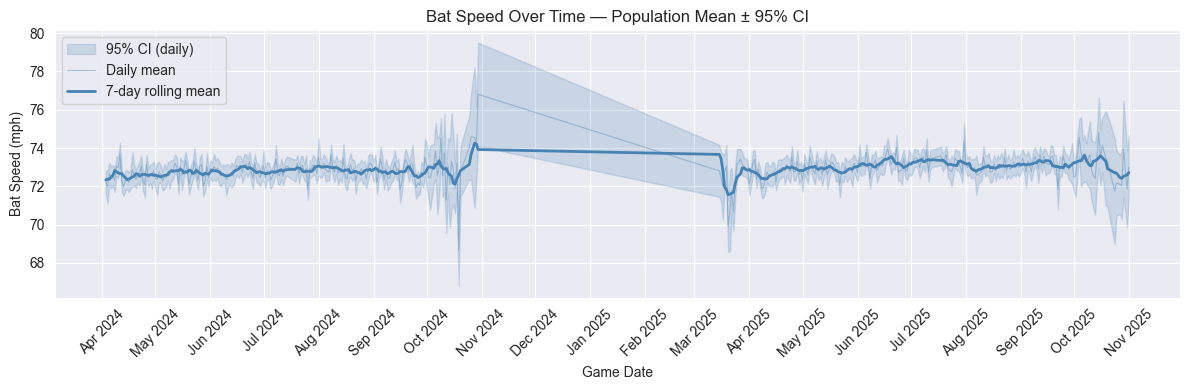

In [35]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# --- Aggregate by game_date ---
daily = (
    df_clean
    .groupby('game_date')['bat_speed']
    .agg(mean='mean', std='std', n='count')
    .reset_index()
)
daily['game_date'] = pd.to_datetime(daily['game_date'])
daily['se'] = daily['std'] / np.sqrt(daily['n'])
daily['ci_lo'] = daily['mean'] - 1.96 * daily['se']
daily['ci_hi'] = daily['mean'] + 1.96 * daily['se']
daily = daily.sort_values('game_date')

# --- Optional: smooth with rolling 7-day window ---
daily['mean_smooth'] = daily['mean'].rolling(7, center=True, min_periods=3).mean()

# --- Plot ---
fig, ax = plt.subplots(figsize=(12, 4))

ax.fill_between(daily['game_date'], daily['ci_lo'], daily['ci_hi'],
                alpha=0.2, color='steelblue', label='95% CI (daily)')
ax.plot(daily['game_date'], daily['mean'],
        color='steelblue', alpha=0.4, linewidth=0.8, label='Daily mean')
ax.plot(daily['game_date'], daily['mean_smooth'],
        color='steelblue', linewidth=2.0, label='7-day rolling mean')

ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.xticks(rotation=45)

ax.set_xlabel('Game Date')
ax.set_ylabel('Bat Speed (mph)')
ax.set_title('Bat Speed Over Time — Population Mean ± 95% CI')
ax.legend()
plt.tight_layout()
plt.show()

In [38]:
within_sd  = df_model.groupby('batter')['bat_speed'].std().mean()
between_sd = df_model.groupby('batter')['bat_speed'].mean().std()
icc = between_sd**2 / (between_sd**2 + within_sd**2)
print(f"Within-player SD:  {within_sd:.3f}")
print(f"Between-player SD: {between_sd:.3f}")
print(f"ICC (theoretical ceiling for test-retest r): {icc:.3f}")

Within-player SD:  3.528
Between-player SD: 2.980
ICC (theoretical ceiling for test-retest r): 0.416


In [41]:
# --- Define solid contact ---
# Tune these thresholds to your domain — q filter already does a lot of work
solid = df_clean[df_clean['q_empirical'].between(0.05, 0.40)].copy()

# --- For each player, compute cumulative mean as swings accumulate ---
solid_sorted = solid.sort_values(['batter', 'game_date'])
solid_sorted['solid_num'] = solid_sorted.groupby('batter').cumcount() + 1
solid_sorted['cum_mean']  = solid_sorted.groupby('batter')['bat_speed'].expanding().mean().values

# --- Full-sample mean as ground truth ---
full_mean = solid.groupby('batter')['bat_speed'].mean().rename('full_mean')
solid_sorted = solid_sorted.join(full_mean, on='batter')

# --- At each k, how far is cumulative mean from full-season mean? ---
records = []
for k in range(1, 31):
    at_k = solid_sorted[solid_sorted['solid_num'] == k].copy()
    at_k['error'] = (at_k['cum_mean'] - at_k['full_mean']).abs()
    records.append({
        'k_solid':   k,
        'mae_mph':   at_k['error'].mean(),
        'n_players': len(at_k),
    })

convergence = pd.DataFrame(records)
print(convergence.to_string(index=False))

 k_solid  mae_mph  n_players
       1 2.429124        837
       2 2.048619        774
       3 1.794217        750
       4 1.540274        734
       5 1.406609        722
       6 1.291362        716
       7 1.223474        706
       8 1.173992        701
       9 1.100876        691
      10 1.030508        682
      11 0.986753        675
      12 0.971893        668
      13 0.940702        663
      14 0.927315        656
      15 0.901999        651
      16 0.894773        644
      17 0.861552        641
      18 0.844722        635
      19 0.826176        630
      20 0.811695        623
      21 0.790146        617
      22 0.767130        612
      23 0.759572        603
      24 0.751676        594
      25 0.735327        591
      26 0.727877        584
      27 0.715983        581
      28 0.706287        576
      29 0.693559        571
      30 0.688985        569


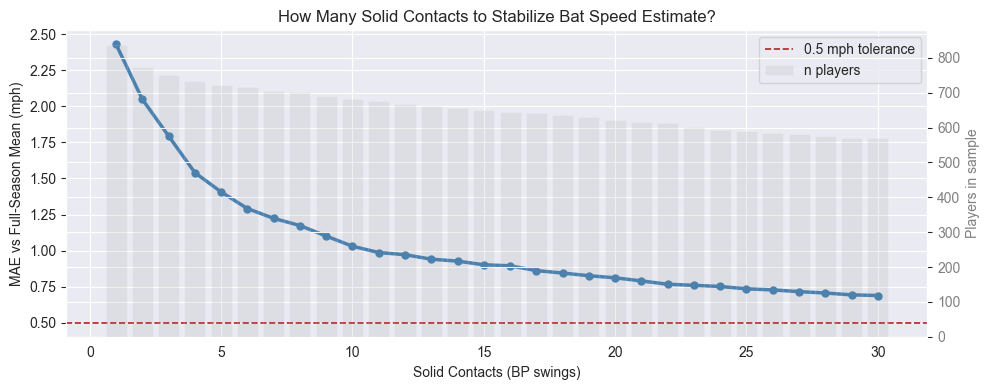

In [42]:
fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(convergence['k_solid'], convergence['mae_mph'],
        color='steelblue', linewidth=2.5, marker='o', markersize=5)

# Shade the "good enough" zone — tune 0.5 mph to your own tolerance
threshold = 0.5
ax.axhline(threshold, color='firebrick', linestyle='--', linewidth=1.2,
           label=f'{threshold} mph tolerance')

# Mark where it first crosses the threshold
crossover = convergence[convergence['mae_mph'] <= threshold]
if not crossover.empty:
    k_cross = crossover['k_solid'].iloc[0]
    ax.axvline(k_cross, color='firebrick', linestyle=':', linewidth=1.2,
               label=f'Crosses threshold at k={k_cross}')

# Annotate n_players falloff on secondary axis
ax2 = ax.twinx()
ax2.bar(convergence['k_solid'], convergence['n_players'],
        alpha=0.12, color='gray', label='n players')
ax2.set_ylabel('Players in sample', color='gray')
ax2.tick_params(axis='y', labelcolor='gray')

ax.set_xlabel('Solid Contacts (BP swings)')
ax.set_ylabel('MAE vs Full-Season Mean (mph)')
ax.set_title('How Many Solid Contacts to Stabilize Bat Speed Estimate?')

lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines1 + lines2, labels1 + labels2, loc='upper right')

plt.tight_layout()
plt.show()

In [43]:
# --- Define solid contact ---
# Tune these thresholds to your domain — q filter already does a lot of work
solid = df_model[df_model['q_empirical'].between(0.05, 0.40)].copy()

# --- For each player, compute cumulative mean as swings accumulate ---
solid_sorted = solid.sort_values(['batter', 'game_date'])
solid_sorted['solid_num'] = solid_sorted.groupby('batter').cumcount() + 1
solid_sorted['cum_mean']  = solid_sorted.groupby('batter')['pred_bat_speed'].expanding().mean().values

# --- Full-sample mean as ground truth ---
full_mean = solid.groupby('batter')['pred_bat_speed'].mean().rename('full_mean')
solid_sorted = solid_sorted.join(full_mean, on='batter')

# --- At each k, how far is cumulative mean from full-season mean? ---
records = []
for k in range(1, 31):
    at_k = solid_sorted[solid_sorted['solid_num'] == k].copy()
    at_k['error'] = (at_k['cum_mean'] - at_k['full_mean']).abs()
    records.append({
        'k_solid':   k,
        'mae_mph':   at_k['error'].mean(),
        'n_players': len(at_k),
    })

convergence = pd.DataFrame(records)
print(convergence.to_string(index=False))

 k_solid  mae_mph  n_players
       1 1.401524        826
       2 1.089978        762
       3 0.897270        744
       4 0.801155        727
       5 0.721427        710
       6 0.664496        699
       7 0.618939        693
       8 0.575480        681
       9 0.544003        671
      10 0.515778        664
      11 0.485647        655
      12 0.465085        650
      13 0.457903        643
      14 0.451876        636
      15 0.434474        626
      16 0.423227        620
      17 0.408398        611
      18 0.390437        606
      19 0.375238        600
      20 0.367211        591
      21 0.355221        582
      22 0.350987        576
      23 0.343899        571
      24 0.326403        566
      25 0.322330        560
      26 0.319648        555
      27 0.315795        547
      28 0.313771        543
      29 0.307646        541
      30 0.305002        538


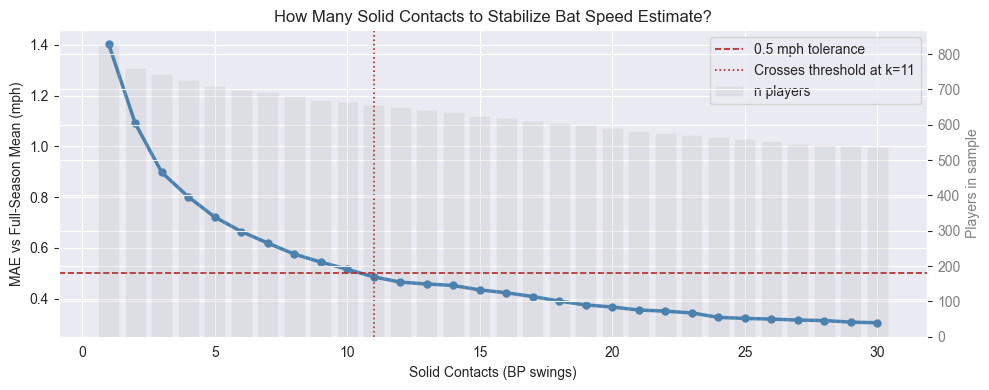

In [44]:
fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(convergence['k_solid'], convergence['mae_mph'],
        color='steelblue', linewidth=2.5, marker='o', markersize=5)

# Shade the "good enough" zone — tune 0.5 mph to your own tolerance
threshold = 0.5
ax.axhline(threshold, color='firebrick', linestyle='--', linewidth=1.2,
           label=f'{threshold} mph tolerance')

# Mark where it first crosses the threshold
crossover = convergence[convergence['mae_mph'] <= threshold]
if not crossover.empty:
    k_cross = crossover['k_solid'].iloc[0]
    ax.axvline(k_cross, color='firebrick', linestyle=':', linewidth=1.2,
               label=f'Crosses threshold at k={k_cross}')

# Annotate n_players falloff on secondary axis
ax2 = ax.twinx()
ax2.bar(convergence['k_solid'], convergence['n_players'],
        alpha=0.12, color='gray', label='n players')
ax2.set_ylabel('Players in sample', color='gray')
ax2.tick_params(axis='y', labelcolor='gray')

ax.set_xlabel('Solid Contacts (BP swings)')
ax.set_ylabel('MAE vs Full-Season Mean (mph)')
ax.set_title('How Many Solid Contacts to Stabilize Bat Speed Estimate?')

lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines1 + lines2, labels1 + labels2, loc='upper right')

plt.tight_layout()
plt.show()

KeyboardInterrupt: 

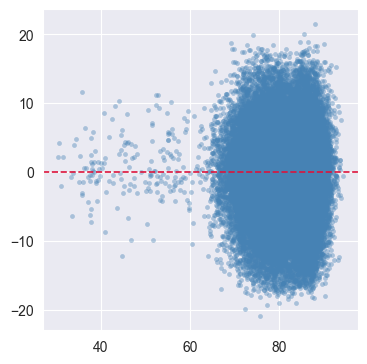

In [25]:
# import matplotlib.pyplot as plt
# import matplotlib.gridspec as gridspec
# import numpy as np
#
# df_holdout['residual'] = df_holdout['bat_speed'] - df_holdout['pred_bat_speed']
#
# features = ['zone_speed', 'launch_angle', 'launch_speed']
# labels = ['Zone Speed (mph)', 'Launch Angle (°)', 'Launch Speed (mph)']
#
# fig = plt.figure(figsize=(15, 10))
# gs = gridspec.GridSpec(2, 3, figure=fig, hspace=0.4, wspace=0.35)
#
# # --- Residuals vs each feature ---
# for i, (feat, label) in enumerate(zip(features, labels)):
#     ax = fig.add_subplot(gs[0, i])
#     ax.scatter(df_holdout[feat], df_holdout['residual'], alpha=0.4, s=12, color='steelblue', linewidths=0)
#     ax.axhline(0, color='crimson', linestyle='--', linewidth=1.2)
#
#     # Optional: LOWESS smoothing trend line
#     from statsmodels.nonparametric.smoothers_lowess import lowess
#     sorted_x = df_holdout[feat].values
#     smooth = lowess(df_holdout['residual'].values, sorted_x, frac=0.3)
#     ax.plot(smooth[:, 0], smooth[:, 1], color='orange', linewidth=1.5, label='LOWESS')
#
#     ax.set_xlabel(label, fontsize=11)
#     ax.set_ylabel('Residual' if i == 0 else '', fontsize=11)
#     ax.set_title(f'Residuals vs {feat}', fontsize=12)
#     ax.legend(fontsize=9)
#     ax.grid(True, alpha=0.2)
#
# # --- Residual histogram ---
# ax_hist = fig.add_subplot(gs[1, 0])
# ax_hist.hist(df_holdout['residual'], bins=40, color='steelblue', edgecolor='white', linewidth=0.4)
# ax_hist.axvline(0, color='crimson', linestyle='--', linewidth=1.2)
# ax_hist.set_xlabel('Residual', fontsize=11)
# ax_hist.set_ylabel('Count', fontsize=11)
# ax_hist.set_title('Residual Distribution', fontsize=12)
# ax_hist.grid(True, alpha=0.2)
#
# # --- Predicted vs Actual ---
# ax_pva = fig.add_subplot(gs[1, 1])
# ax_pva.scatter(df_holdout['pred_bat_speed'], df_holdout['bat_speed'], alpha=0.4, s=12, color='steelblue', linewidths=0)
# lims = [df_holdout[['bat_speed', 'pred_bat_speed']].min().min(),
#         df_holdout[['bat_speed', 'pred_bat_speed']].max().max()]
# ax_pva.plot(lims, lims, color='crimson', linestyle='--', linewidth=1.2)
# ax_pva.set_xlabel('Predicted Bat Speed', fontsize=11)
# ax_pva.set_ylabel('Actual Bat Speed', fontsize=11)
# ax_pva.set_title('Predicted vs Actual', fontsize=12)
# ax_pva.grid(True, alpha=0.2)
#
# # --- Residuals vs Predicted (heteroscedasticity check) ---
# ax_rvp = fig.add_subplot(gs[1, 2])
# ax_rvp.scatter(df_holdout['pred_bat_speed'], df_holdout['residual'], alpha=0.4, s=12, color='steelblue', linewidths=0)
# ax_rvp.axhline(0, color='crimson', linestyle='--', linewidth=1.2)
# ax_rvp.set_xlabel('Predicted Bat Speed', fontsize=11)
# ax_rvp.set_ylabel('Residual', fontsize=11)
# ax_rvp.set_title('Residuals vs Predicted', fontsize=12)
# ax_rvp.grid(True, alpha=0.2)
#
# fig.suptitle('XGBoost Bat Speed — Residual Diagnostics (Holdout Set)', fontsize=14, fontweight='500', y=1.01)
# plt.savefig('residual_plots.png', dpi=150, bbox_inches='tight')
# plt.show()

C:\Users\215nt\PycharmProjects\FLStuff\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


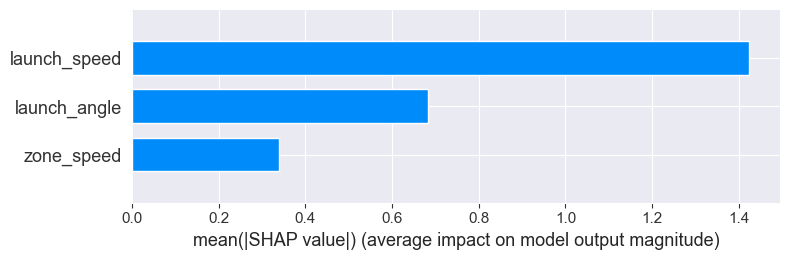

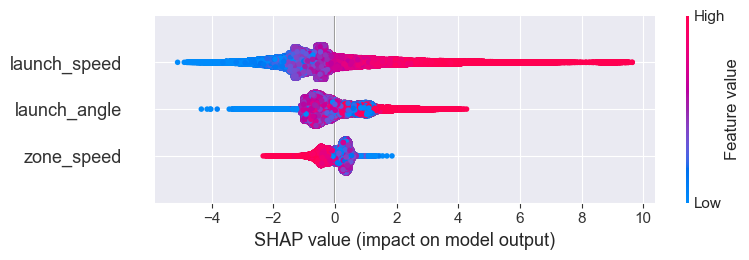

In [22]:
import shap

# 1. Initialize the SHAP Explainer
# TreeExplainer is optimized for Random Forest, XGBoost, LightGBM, etc.
explainer = shap.TreeExplainer(final_model)

# 2. Calculate SHAP values for your validation/test set
# This might take a moment depending on the size of X_val
shap_values = explainer.shap_values(X_dev)

# 3. Visualize Feature Importance (Summary Plot)
# This replaces your barh plot with a much more informative version
shap.summary_plot(shap_values, X_dev, plot_type="bar")

# 4. Visualize Impact (Beeswarm Plot)
# This shows both importance AND whether high/low values help or hurt the prediction
shap.summary_plot(shap_values, X_dev)

In [51]:
# 1. Generate predictions for the Holdout set
df_holdout = df_holdout.copy()
df_holdout['pred_bat_speed'] = final_model.predict(df_holdout[features])

# 2. Group by batter to calculate player-level averages and sample size
player_holdout = df_holdout.groupby('batter').agg({
    'bat_speed': 'mean',
    'pred_bat_speed': 'mean',
    'launch_angle': 'mean',
    'zone_speed': 'mean',
    'efficiency': 'mean',
    'launch_speed': ['mean', 'count'] # Perform both on one column
})

# Flatten the MultiIndex columns created by the list above
player_holdout.columns = [
    'bat_speed', 'pred_bat_speed', 'launch_angle',
    'zone_speed', 'efficiency', 'avg_launch_speed', 'swing_count'
]

# 3. Apply the Minimum Swing Filter
# 10-20 swings is usually enough to see the 'signal' in a holdout set
min_swings = 3
qualified_holdout = player_holdout[player_holdout['swing_count'] >= min_swings].copy()

# 4. Calculate Final Metrics
agg_rmse = np.sqrt(mean_squared_error(qualified_holdout['bat_speed'], qualified_holdout['pred_bat_speed']))
agg_corr = qualified_holdout['bat_speed'].corr(qualified_holdout['pred_bat_speed'])
agg_r2 = agg_corr**2

print(f"--- Aggregated Results (Min Swings: {min_swings}) ---")
print(f"Qualified Players: {len(qualified_holdout)}")
print(f"Aggregated RMSE:   {agg_rmse:.4f} mph")
print(f"Aggregated R2:     {agg_r2:.4f}")
print(f"Correlation:       {agg_corr:.4f}")

--- Aggregated Results (Min Swings: 3) ---
Qualified Players: 742
Aggregated RMSE:   2.5163 mph
Aggregated R2:     0.3894
Correlation:       0.6240


In [24]:
# 1. Aggregate swing_length by batter from your cleaned source data
player_swing_lengths = df_clean.groupby('batter')['swing_length'].mean()

# 2. Join this to your qualified_holdout DataFrame
# Since both are indexed by 'batter', a simple join works perfectly
qualified_holdout = qualified_holdout.join(player_swing_lengths, how='left')

# 3. Calculate the 'Speed Gap' (Residual) within this aggregated DF
# Residual = Predicted - Actual
qualified_holdout['speed_gap'] = (
    qualified_holdout['bat_speed'] - qualified_holdout['final_bat_speed']
)

# Preview the new structure
print(qualified_holdout[['bat_speed', 'final_bat_speed', 'speed_gap', 'swing_length']].head())

KeyError: 'final_bat_speed'

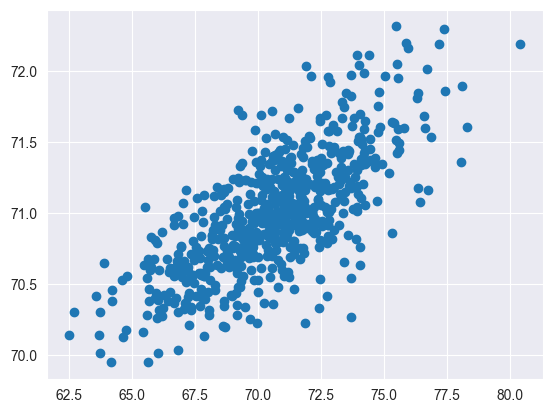

In [107]:
plt.scatter(qualified_holdout['bat_speed'], qualified_holdout['final_bat_speed'])

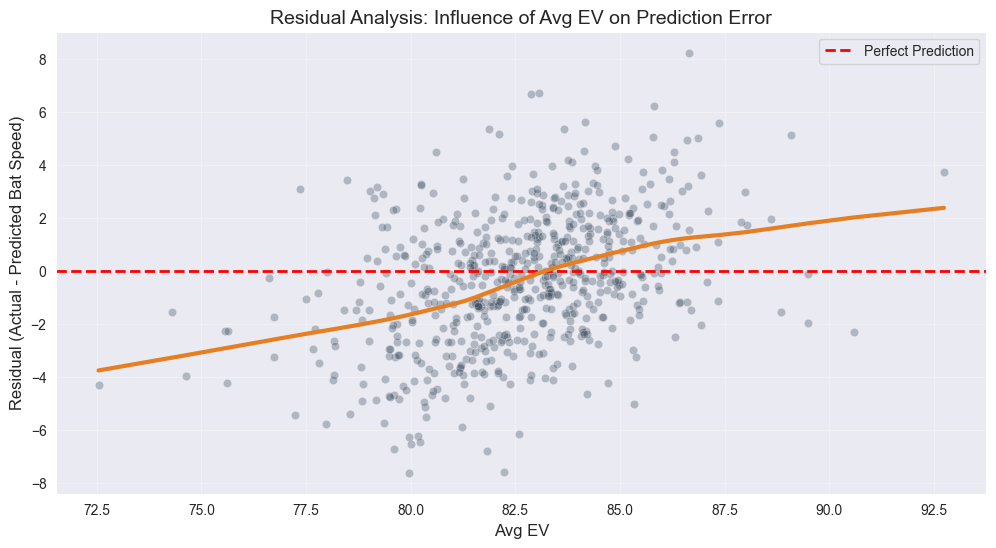

In [109]:
import matplotlib.pyplot as plt
import seaborn as sns

qualified_holdout['speed_gap'] = qualified_holdout['bat_speed'] - qualified_holdout['final_bat_speed']

# 2. Create the Plot
plt.figure(figsize=(12, 6))

# Scatter plot with transparency to handle density
sns.scatterplot(
    data=qualified_holdout,
    x='avg_launch_speed',
    y='speed_gap',
    alpha=0.3,
    color='#2c3e50'
)

# Add a horizontal line at 0 (Perfect Prediction)
plt.axhline(0, color='red', linestyle='--', lw=2, label='Perfect Prediction')

# Add a Lowess trend line to see systematic bias
sns.regplot(
    data=qualified_holdout,
    x='avg_launch_speed',
    y='speed_gap',
    scatter=False,
    lowess=True,
    line_kws={'color': '#e67e22', 'lw': 3, 'label': 'Bias Trend'}
)

plt.title('Residual Analysis: Influence of Avg EV on Prediction Error', fontsize=14)
plt.xlabel('Avg EV', fontsize=12)
plt.ylabel('Residual (Actual - Predicted Bat Speed)', fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

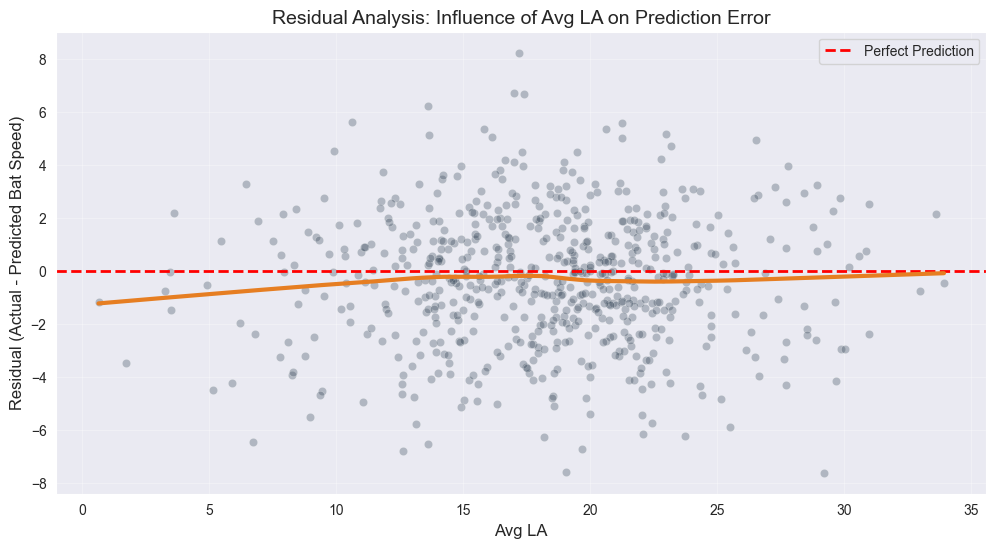

In [110]:
import matplotlib.pyplot as plt
import seaborn as sns



# 2. Create the Plot
plt.figure(figsize=(12, 6))

# Scatter plot with transparency to handle density
sns.scatterplot(
    data=qualified_holdout,
    x='launch_angle',
    y='speed_gap',
    alpha=0.3,
    color='#2c3e50'
)

# Add a horizontal line at 0 (Perfect Prediction)
plt.axhline(0, color='red', linestyle='--', lw=2, label='Perfect Prediction')

# Add a Lowess trend line to see systematic bias
sns.regplot(
    data=qualified_holdout,
    x='launch_angle',
    y='speed_gap',
    scatter=False,
    lowess=True,
    line_kws={'color': '#e67e22', 'lw': 3, 'label': 'Bias Trend'}
)

plt.title('Residual Analysis: Influence of Avg LA on Prediction Error', fontsize=14)
plt.xlabel('Avg LA', fontsize=12)
plt.ylabel('Residual (Actual - Predicted Bat Speed)', fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

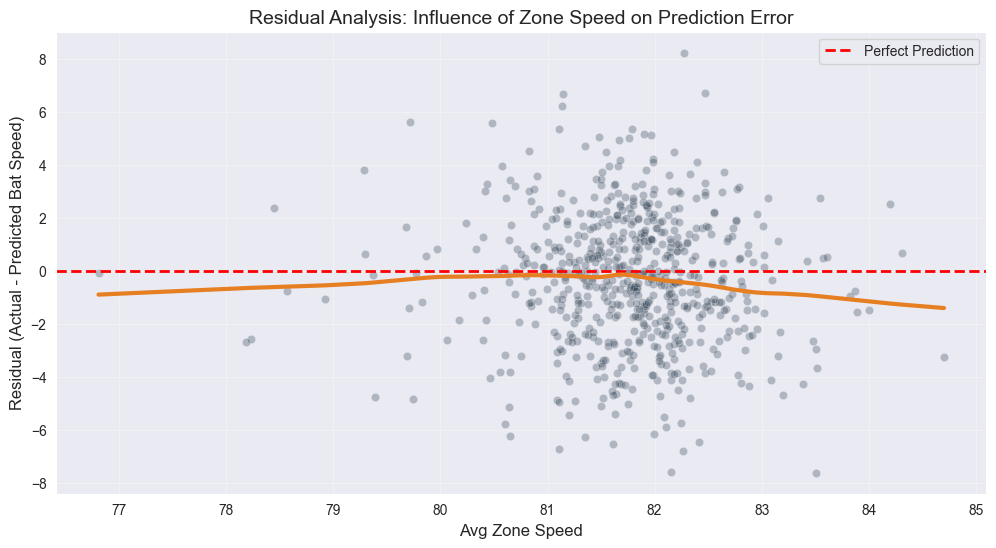

In [111]:
plt.show()
import matplotlib.pyplot as plt
import seaborn as sns

# 2. Create the Plot
plt.figure(figsize=(12, 6))

# Scatter plot with transparency to handle density
sns.scatterplot(
    data=qualified_holdout,
    x='zone_speed',
    y='speed_gap',
    alpha=0.3,
    color='#2c3e50'
)

# Add a horizontal line at 0 (Perfect Prediction)
plt.axhline(0, color='red', linestyle='--', lw=2, label='Perfect Prediction')

# Add a Lowess trend line to see systematic bias
sns.regplot(
    data=qualified_holdout,
    x='zone_speed',
    y='speed_gap',
    scatter=False,
    lowess=True,
    line_kws={'color': '#e67e22', 'lw': 3, 'label': 'Bias Trend'}
)

plt.title('Residual Analysis: Influence of Zone Speed on Prediction Error', fontsize=14)
plt.xlabel('Avg Zone Speed', fontsize=12)
plt.ylabel('Residual (Actual - Predicted Bat Speed)', fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

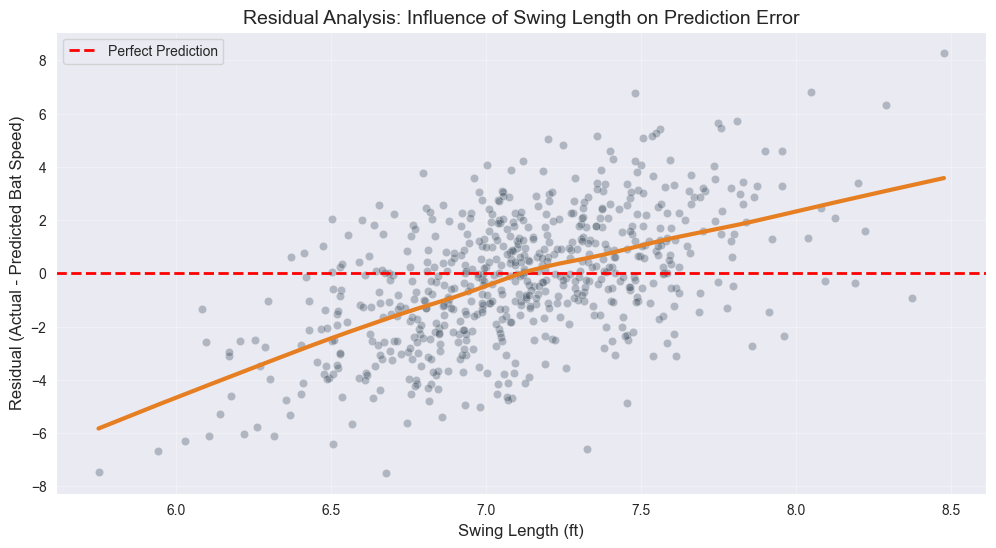

In [71]:
import matplotlib.pyplot as plt
import seaborn as sns



# 2. Create the Plot
plt.figure(figsize=(12, 6))

# Scatter plot with transparency to handle density
sns.scatterplot(
    data=qualified_holdout,
    x='swing_length',
    y='speed_gap',
    alpha=0.3,
    color='#2c3e50'
)

# Add a horizontal line at 0 (Perfect Prediction)
plt.axhline(0, color='red', linestyle='--', lw=2, label='Perfect Prediction')

# Add a Lowess trend line to see systematic bias
sns.regplot(
    data=qualified_holdout,
    x='swing_length',
    y='speed_gap',
    scatter=False,
    lowess=True,
    line_kws={'color': '#e67e22', 'lw': 3, 'label': 'Bias Trend'}
)

plt.title('Residual Analysis: Influence of Swing Length on Prediction Error', fontsize=14)
plt.xlabel('Swing Length (ft)', fontsize=12)
plt.ylabel('Residual (Actual - Predicted Bat Speed)', fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

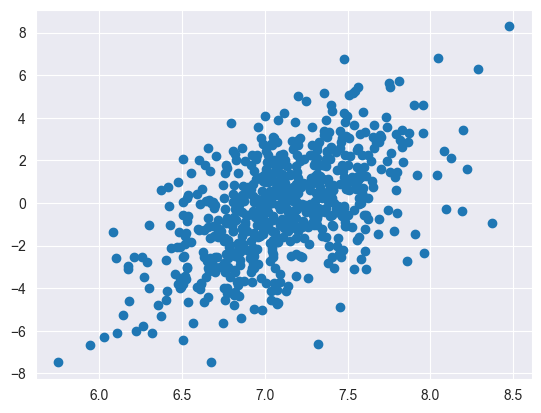

In [72]:
plt.scatter(qualified_holdout['swing_length'], qualified_holdout['speed_gap'])

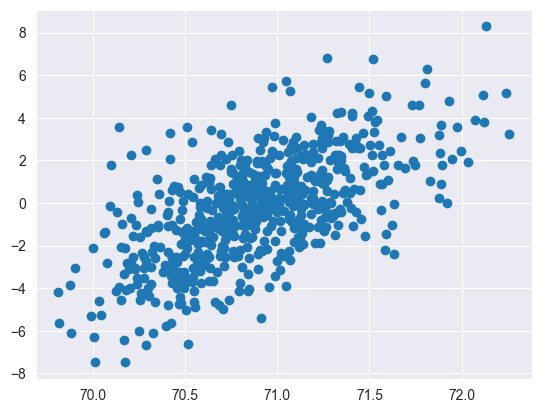

In [73]:
plt.scatter(qualified_holdout['pred_bat_speed'], qualified_holdout['speed_gap'])

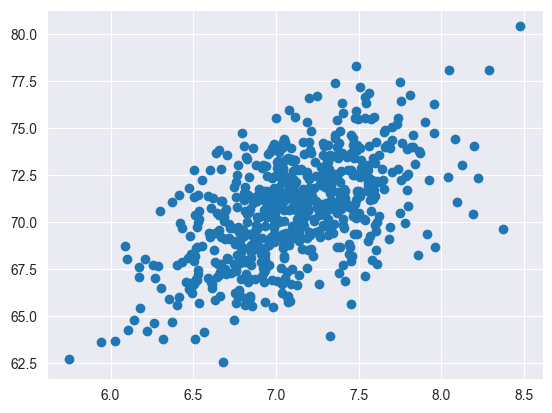

In [41]:
plt.scatter(qualified_holdout['swing_length'], qualified_holdout['bat_speed'])

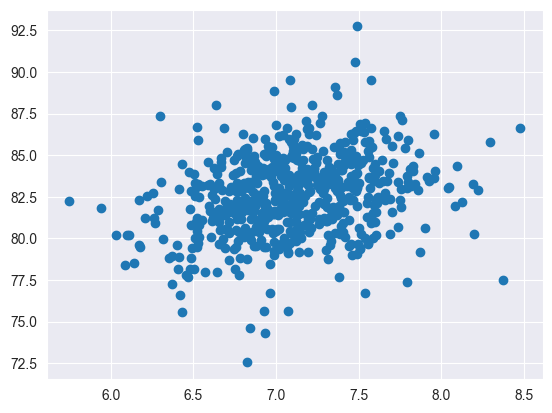

In [46]:
plt.scatter(qualified_holdout['swing_length'], qualified_holdout['avg_launch_speed'])

C:\Users\215nt\AppData\Local\Temp\ipykernel_148976\213597751.py:8: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot = qualified_holdout.pivot_table(


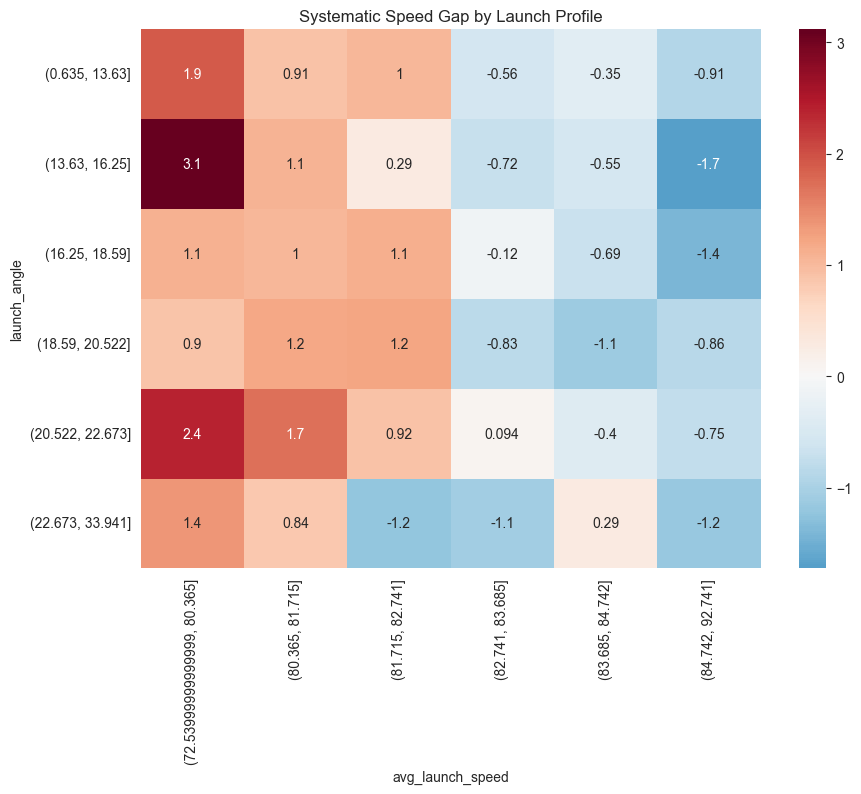

In [37]:
import seaborn as sns
import matplotlib.pyplot as plt

qualified_holdout['speed_gap'] = qualified_holdout['pred_bat_speed'] - qualified_holdout['bat_speed']
# We want to see how the Speed Gap (Residual) behaves across
# Launch Angle and Launch Speed simultaneously.
plt.figure(figsize=(10, 7))
pivot = qualified_holdout.pivot_table(
    index=pd.qcut(qualified_holdout['launch_angle'], 6),
    columns=pd.qcut(qualified_holdout['avg_launch_speed'], 6),
    values='speed_gap', # (Pred - Actual)
    aggfunc='mean'
)

sns.heatmap(pivot, annot=True, cmap='RdBu_r', center=0)
plt.title('Systematic Speed Gap by Launch Profile')
plt.show()

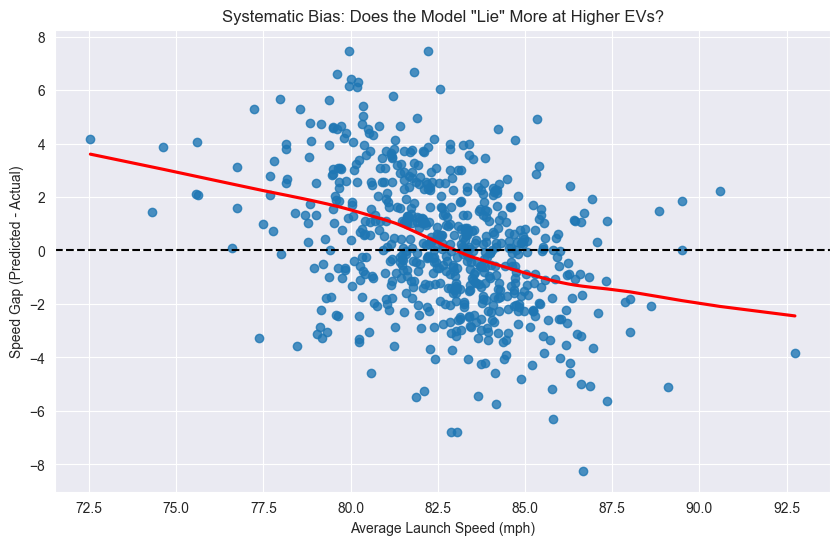

In [38]:
import seaborn as sns
import matplotlib.pyplot as plt

# Plotting the 'Speed Gap' against Average Launch Speed
plt.figure(figsize=(10, 6))
sns.regplot(data=qualified_holdout, x='avg_launch_speed', y='speed_gap',
            lowess=True, line_kws={'color': 'red'})
plt.axhline(0, color='black', linestyle='--')
plt.title('Systematic Bias: Does the Model "Lie" More at Higher EVs?')
plt.xlabel('Average Launch Speed (mph)')
plt.ylabel('Speed Gap (Predicted - Actual)')
plt.show()

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error

def bootstrap_metrics(df, n_iterations=1000, min_swings=15):
    # Get the unique list of players
    unique_players = df['batter'].unique()
    boot_rmse, boot_corr = [], []

    for _ in range(n_iterations):
        # 1. Resample PLAYERS with replacement
        resampled_players = np.random.choice(unique_players, size=len(unique_players), replace=True)

        # 2. Grab all swings for those players
        # (Note: if a player is picked twice, they appear twice in the sample)
        sample_list = [df[df['batter'] == p] for p in resampled_players]
        sample_df = pd.concat(sample_list)

        # 3. Aggregate
        agg = sample_df.groupby('batter').agg({
            'bat_speed': 'mean',
            'pred_bat_speed': 'mean',
            'launch_speed': 'count'
        })

        qualified = agg[agg['launch_speed'] >= min_swings]

        if len(qualified) > 1:
            boot_rmse.append(np.sqrt(mean_squared_error(qualified['bat_speed'], qualified['pred_bat_speed'])))
            boot_corr.append(qualified['bat_speed'].corr(qualified['pred_bat_speed']))

    return np.array(boot_rmse), np.array(boot_corr)

# Execute the bootstrap
rmse_dist, corr_dist = bootstrap_metrics(df_holdout)

# 4. Calculate Percentile-based Intervals (95% CI)
rmse_ci = np.percentile(rmse_dist, [2.5, 97.5])
corr_ci = np.percentile(corr_dist, [2.5, 97.5])

print(f"--- Bootstrapped 95% Intervals ---")
print(f"Aggregated RMSE: {rmse_dist.mean():.4f} mph (CI: {rmse_ci[0]:.4f} - {rmse_ci[1]:.4f})")
print(f"Correlation:     {corr_dist.mean():.4f} (CI: {corr_ci[0]:.4f} - {corr_ci[1]:.4f})")